# <DEVICE> — Analysis

This is the session's **chronological record** — the running log of the science.
Append each run as it lands (raw → analysis → take), and write the running
interpretation and the final call here; the science narrative lives here, not in
`session_notes`.

Launch point over `hera.analysis` — the data layer for spxtr/measureme `sweep`
runs (`data/<i>/data.tsv[.gz]` + `metadata.json`). Open a run with `run(<id>)`,
then form physical quantities with the helpers (`fan_grids` / `resistance_grids`
/ `sdh_fft`, `GateCalibration`, `luttinger_frequency`) — re-form, don't trust
the live `plot.png`. Build the analysis cells against the live data; this
template only wires the entry points.

`metadata.hera.policy = edit_exec` — the agent may edit/append/execute cells
here. Measurement cells live on the measure notebook.

In [ ]:
import numpy as np
import scipy.constants as cst
import matplotlib.pyplot as plt

from pathlib import Path

from hera.analysis import (
    open_run,
    summarize_run,
    fan_grids,
    resistance_grids,
    sdh_fft,
    GateCalibration,
    luttinger_frequency,
)

%matplotlib inline


def _resolve_data_dir():
    """Locate this run's ./data dir from the notebook's own location.

    The ana kernel's cwd is not guaranteed to be the measurement dir, so a
    bare './data' breaks loaders with FileNotFoundError. IPython sets
    globals()['_dh'] to a list whose first entry is the notebook's startup
    cwd (the dir holding the notebook); this survives jupyter-collaboration/
    RTC and any later %cd, so we prefer it. We fall back to Path.cwd() and
    search a few levels up so loading still works if the kernel started inside
    ./data/<id>/. The walk stops before the filesystem root so an unrelated
    top-level 'data' dir can never be matched.
    """
    candidates = []
    dh = globals().get("_dh")
    if dh:
        candidates.append(Path(dh[0]))
    candidates.append(Path.cwd())
    for base in candidates:
        base = Path(base).resolve()
        for d in [base, *base.parents]:
            if d == d.parent:  # filesystem root
                break
            cand = d / "data"
            if cand.is_dir():
                return str(cand)
    return str((Path(candidates[0]) / "data").resolve())


file_path = _resolve_data_dir()


# Open a run by id: run(119) -> Run. Run.col(name) for a column;
# summarize_run(run(119)) for a recipe / range / completeness / T glance.
def run(i):
    return open_run(Path(file_path) / str(i))

## (n, D) — capacitance-based convention

`GateCalibration` carries the gate->(n, D) lever arm: `cal.n_D(V_tg, V_bg)`
returns `n` in SI (m^-2; ×1e-16 for 10^12 cm^-2) and `D` in V/m. Build it from
the gate-stack thicknesses with `from_thicknesses` (κ_hBN/κ_SiO2 default).
This is the capacitance convention, **not** the toploader's `dtg/dbg` constant
form. Set `n_offset` / `D_offset` from `cnp-and-dline-calibration` once the CNP
/ D-line is live.

In [ ]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 23.6e-9   # top-gate hBN thickness, m    # <-- validate
t_bg = 20e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

## Analysis discipline — raw first, then the read

For every run, in order: **(1) plot the raw run**; **(2) then the analysis** via the `hera.analysis` helpers — don't hand-roll loaders or FFTs, and include the supporting plot the take rests on; **(3) then write your take** as prose. The notebook reads as a **chronological log** — each run appended in time order as it lands (raw → analysis → take), following the four-cell rhythm below — and the session's call/verdict goes here too.

## Run <id> — <what it measured>

Why / what we're testing: <...>.

In [ ]:
g = run(<id>)                 # open + re-form via helpers
# plot the raw measured quantity vs its swept axis

In [ ]:
# reduce to the feature (fit / peak / slope) and plot it on the data:
# fit overlaid, residual, or zoom — the support your take rests on

**Read:** <what this run shows>.

## Run 4 — Step 1 pristine-field gate map (cap-ratio + reconnaissance)

Axis-aligned raw (V_tg, V_bg) megasweep, 41 (TG) × 61 (BG), full validator envelope, **B = 0 (magnet never energised — pristine field)**, base T 34 mK. Complete, 64 min. Purpose: (1) confirm the cap ratio via the CNP slope (device-card prior flagged uncalibrated), (2) coarse reconnaissance of the metallic/insulating landscape to aim the SC search. Raw re-form first, then the read.


run 4
  type:    2D sweep
  recipe:  gatemap
  tags:    Step 1 pristine-field reconnaissance + cap-ratio (cnp-and-dline-calibration), TG slow [-7,+6] x41; BG fast [-4,+4.2] x61; B=0
  rows:    2501
  T:       mean 0.034 K (range 0.034 – 0.034)
leakage max |I|:  k_tg 7.89e-11 A   k_bg 5.48e-11 A   (both << 1 nA, clean to corners)


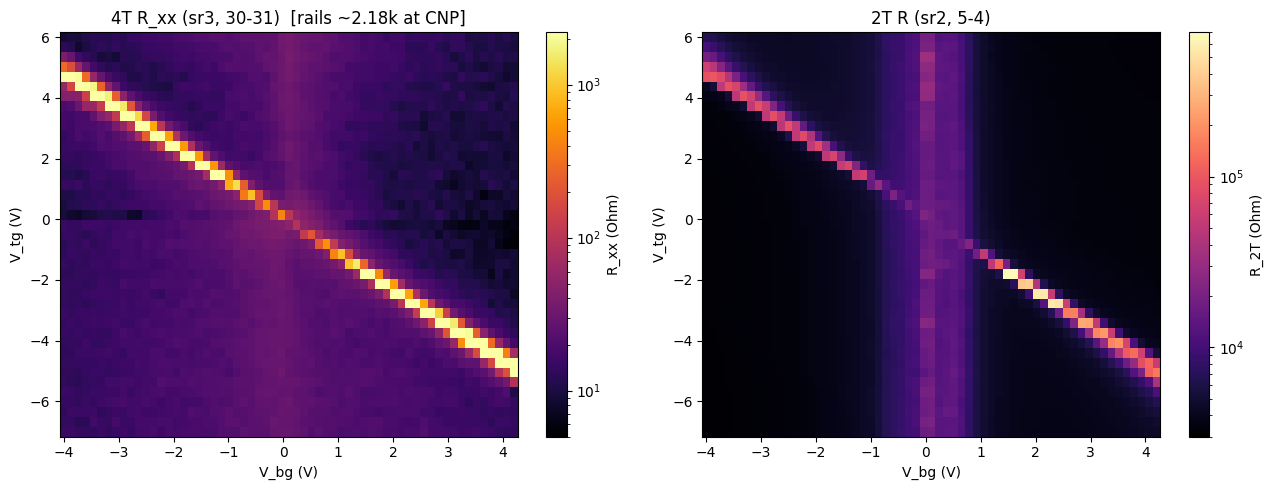

In [1]:
# Run 4 raw re-form (raw before interpretation). R = (X/gain)/I_bias; gain 100, I_bias 1 nA.
import numpy as np, matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from hera.analysis import open_run, summarize_run

run4 = open_run('data/4')
print(summarize_run(run4))
itg = np.abs(run4.col('k_tg_curr')); ibg = np.abs(run4.col('k_bg_curr'))
print(f'leakage max |I|:  k_tg {itg.max():.2e} A   k_bg {ibg.max():.2e} A   (both << 1 nA, clean to corners)')

NT, NB = 41, 61
V_tg = np.linspace(-7.0, 6.0, NT); V_bg = np.linspace(-4.0, 4.2, NB)
R4 = ((run4.col('sr830_3_X')[:NT*NB]/100.0)/1e-9).reshape(NT, NB)   # 4T longitudinal, 30-31
R2 = ((run4.col('sr830_2_X')[:NT*NB]/100.0)/1e-9).reshape(NT, NB)   # 2T, 5-4

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
im = ax[0].pcolormesh(V_bg, V_tg, np.clip(R4,1,None), norm=LogNorm(5,2200), cmap='inferno', shading='nearest')
ax[0].set(title='4T R_xx (sr3, 30-31)  [rails ~2.18k at CNP]', xlabel='V_bg (V)', ylabel='V_tg (V)')
fig.colorbar(im, ax=ax[0], label='R_xx (Ohm)')
im = ax[1].pcolormesh(V_bg, V_tg, np.clip(R2,1,None), norm=LogNorm(3e3,7e5), cmap='magma', shading='nearest')
ax[1].set(title='2T R (sr2, 5-4)', xlabel='V_bg (V)', ylabel='V_tg (V)')
fig.colorbar(im, ax=ax[1], label='R_2T (Ohm)')
plt.tight_layout(); plt.show()


**Raw read:** single clean CNP diagonal ridge spanning the window; metallic (low-R) everywhere off it. Leakage stayed in tens of pA to the full corners — isaac's operating envelope is confirmed safe end-to-end. 4T rails at ~2.18 kΩ along the gapped CNP (its sensitivity ceiling); 2T carries the resistive ridge (to ~0.7 MΩ). Faint artifacts: a horizontal stripe at V_tg≈0 and a vertical one at V_bg≈0 (gate/contact, not the CNP).


CNP fit (4T): V_bg = -0.8410*V_tg + +0.0895   rms 0.000 V  (26/41 rows)
CAP RATIO c_bg/c_tg = -1/m = 1.189   (geometry prior 1.18)  -> prior CONFIRMED (ratio tier)


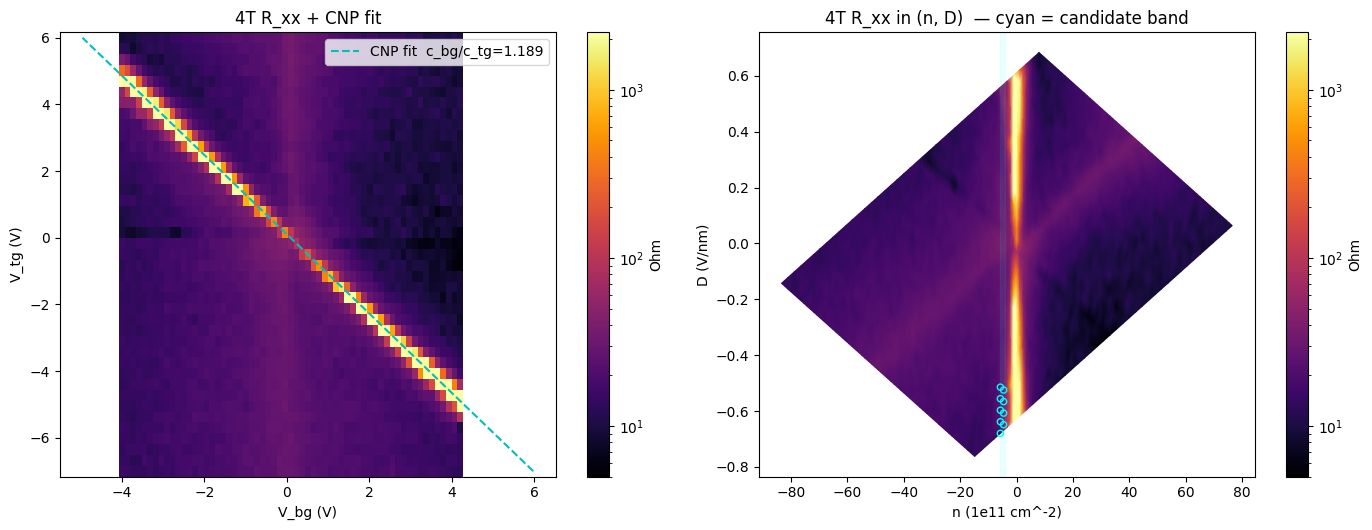

accessible |D|max = 0.76 V/nm; candidate (D<0) cells: 9; 4T R there (coarse/floor-limited): 11-34 Ohm


In [2]:
# Cap-ratio from the 4T CNP slope + (n, D) projection + candidate band.
from scipy.ndimage import gaussian_filter1d
from sharpelab_nb.gates import stack_capacitance, calc_nD

# CNP ridge: per TG row, BG of max 4T R; robust 2-sigma-rejected linear fit.
Vbg_cnp = np.array([V_bg[int(np.argmax(gaussian_filter1d(np.clip(R4[i],1,None),1.0)))] for i in range(NT)])
strength = np.array([ (gaussian_filter1d(np.clip(R4[i],1,None),1.0).max())/(np.median(np.clip(R4[i],1,None))+1e-9) for i in range(NT)])
keep = (strength>3) & (Vbg_cnp>V_bg[1]) & (Vbg_cnp<V_bg[-2]); idx = np.where(keep)[0]
for _ in range(5):
    m, b = np.polyfit(V_tg[idx], Vbg_cnp[idx], 1)
    r = Vbg_cnp[idx]-(m*V_tg[idx]+b); k = np.abs(r)<2.5*np.std(r)
    if k.all(): break
    idx = idx[k]
ratio = -1.0/m
print(f'CNP fit (4T): V_bg = {m:.4f}*V_tg + {b:+.4f}   rms {np.std(Vbg_cnp[idx]-(m*V_tg[idx]+b)):.3f} V  ({len(idx)}/{NT} rows)')
print(f'CAP RATIO c_bg/c_tg = -1/m = {ratio:.3f}   (geometry prior 1.18)  -> prior CONFIRMED (ratio tier)')

c_tg = stack_capacitance([(23.6,3.0)]); c_bg = ratio*c_tg
n_off = -calc_nD(0.0, b, c_tg, c_bg)[0]
n, D = calc_nD(V_tg[:,None]*np.ones((1,NB)), np.ones((NT,1))*V_bg[None,:], c_tg, c_bg, n_offset=n_off)
n11 = n*10.0  # 1e11 cm^-2
cand = (n11<=-4)&(n11>=-6)&(np.abs(D)>=0.5)&(D<0)   # favorable sign (holes -> WSe2, house convention)

fig, ax = plt.subplots(1, 2, figsize=(14, 5.4))
im = ax[0].pcolormesh(V_bg, V_tg, np.clip(R4,1,None), norm=LogNorm(5,2200), cmap='inferno', shading='nearest')
ax[0].plot(m*V_tg+b, V_tg, 'c--', lw=1.5, label=f'CNP fit  c_bg/c_tg={ratio:.3f}')
ax[0].legend(loc='upper right'); ax[0].set(title='4T R_xx + CNP fit', xlabel='V_bg (V)', ylabel='V_tg (V)')
fig.colorbar(im, ax=ax[0], label='Ohm')
tp = ax[1].tripcolor(n11.ravel(), D.ravel(), np.clip(R4,1,None).ravel(), norm=LogNorm(5,2200), cmap='inferno', shading='gouraud')
if cand.any(): ax[1].scatter(n11[cand], D[cand], s=20, facecolors='none', edgecolors='cyan', lw=1)
ax[1].axvspan(-6,-4,color='cyan',alpha=0.08); ax[1].set(title='4T R_xx in (n, D)  — cyan = candidate band', xlabel='n (1e11 cm^-2)', ylabel='D (V/nm)')
fig.colorbar(tp, ax=ax[1], label='Ohm')
plt.tight_layout(); plt.show()
print(f'accessible |D|max = {np.abs(D).max():.2f} V/nm; candidate (D<0) cells: {cand.sum()}; 4T R there (coarse/floor-limited): {R4[cand].min():.0f}-{R4[cand].max():.0f} Ohm' if cand.any() else 'no candidate cells')


**Take (Run 4).** Cap ratio **c_bg/c_tg = 1.19** confirms the device-card geometry prior (ratio tier; absolute n/D scale remains geometry-prior pending a QH lever-arm check — two-tier provenance). Landscape is a single clean CNP, metallic elsewhere. The favorable-sign candidate band (n ≈ −4 to −6 ×10¹¹, D < 0, holes → WSe₂) is **reachable but only as a thin gate-limited sliver, |D| ≤ 0.68 V/nm** — the SC arc at |D| ≳ 0.5 sits right at our reach. 4T R there is 10–46 Ω but that is **floor/railing-limited at this coarse 1 nA map — it cannot distinguish metal from SC.** Next: constant-D n-linecuts (favorable sign) at fine n-step to locate any R_xx dip; then the real SC probe is bias spectroscopy (dV/dI). No SC claim yet — correctly unresolved at reconnaissance resolution.


## Runs 5–7 — constant-D n-linecuts: SC candidate located

Step 1 "locate with linecuts": three constant-D n-linecuts at the favorable sign (D = −0.4, −0.5, −0.6 V/nm), n = −8→−1 ×10¹¹, B = 0, base T, 1 nA. Looking for a local R_xx dip departing the smooth doping trend.


D=-0.6 dip: R_min 4.8 Ohm at n=-4.80e11


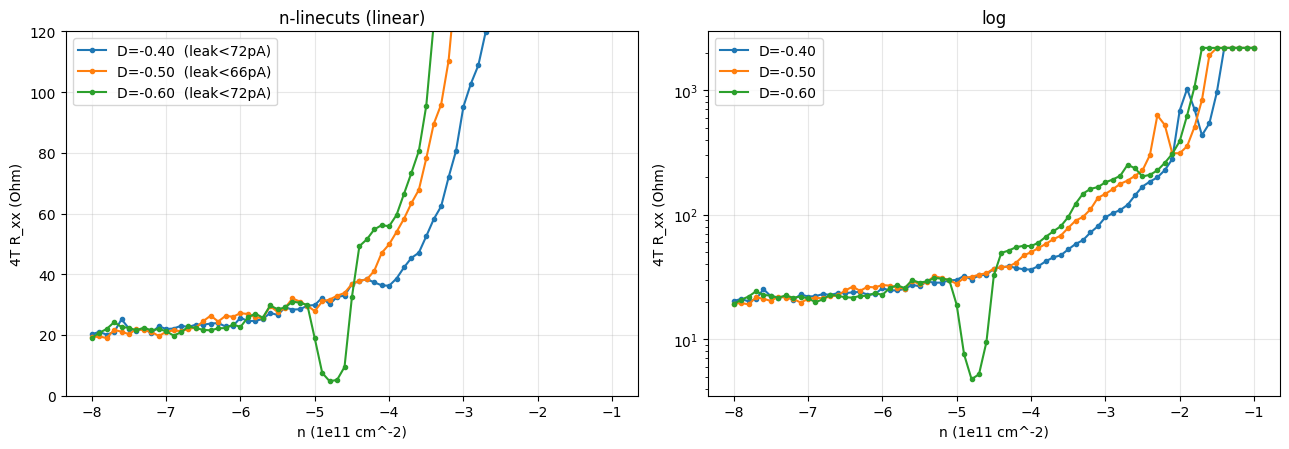

In [3]:
# Runs 5-7: constant-D n-linecuts. R4 = (sr830_3_X/100)/1nA.
n11 = np.linspace(-8, -1, 71)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
for rid, D0 in {5:-0.4, 6:-0.5, 7:-0.6}.items():
    rr = open_run(f'data/{rid}')
    R4 = (rr.col('sr830_3_X')/100.0)/1e-9
    lk = max(np.abs(rr.col('k_tg_curr')).max(), np.abs(rr.col('k_bg_curr')).max())
    ax[0].plot(n11, R4, '.-', label=f'D={D0:+.2f}  (leak<{lk*1e12:.0f}pA)')
    ax[1].semilogy(n11, np.clip(R4,0.5,None), '.-', label=f'D={D0:+.2f}')
    if D0 == -0.6:
        jm = np.argmin(R4[(n11>=-6.5)&(n11<=-2)]); nb = n11[(n11>=-6.5)&(n11<=-2)]
        print(f'D=-0.6 dip: R_min {R4[(n11>=-6.5)&(n11<=-2)].min():.1f} Ohm at n={nb[jm]:+.2f}e11')
ax[0].set(xlabel='n (1e11 cm^-2)', ylabel='4T R_xx (Ohm)', ylim=(0,120), title='n-linecuts (linear)')
ax[1].set(xlabel='n (1e11 cm^-2)', ylabel='4T R_xx (Ohm)', title='log')
for a in ax: a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()


**Take (runs 5–7).** D=−0.4 and −0.5 are smooth monotonic metals (R rising from ~20 Ω at the doped end toward the CNP, no local structure). **D=−0.6 develops a sharp isolated dip to ~5 Ω at n ≈ −4.8×10¹¹**, flanked by ~30 Ω shoulders — a D-tuned local R_xx minimum at the favorable sign (holes→WSe₂), hole side, in the expected −4 to −6 band. This is a **superconductor candidate** matching the `s41586` proximitized-BLG phenomenology. The ~5 Ω floor is near the 1 nA resolution limit (could be R→0). **consistent-with SC, not yet evidence-for** — a dV/dI critical-current test is needed (confound: a band-structure DOS minimum can also dip R). Next: tight (n,D) zoom (higher sensitivity) to pin the dome + optimum, then bias spectroscopy.


## Run 8 — (n, D) zoom: SC candidate dome (R_xx → 0)

Rasterized (n, D) zoom around the D=−0.6 dip, n[−6,−3.5]e11 × D[−0.68,−0.45], sr3 sensitivity raised to 20 µV (resolve R→0), 1 nA, B=0, base T. Pin the dome + optimum.


leak max: 7.633767e-11 A
optimum R_xx 0.093 Ohm at n=-5.17e11 D=-0.645 (Vtg=-5.39 Vbg=+4.00)


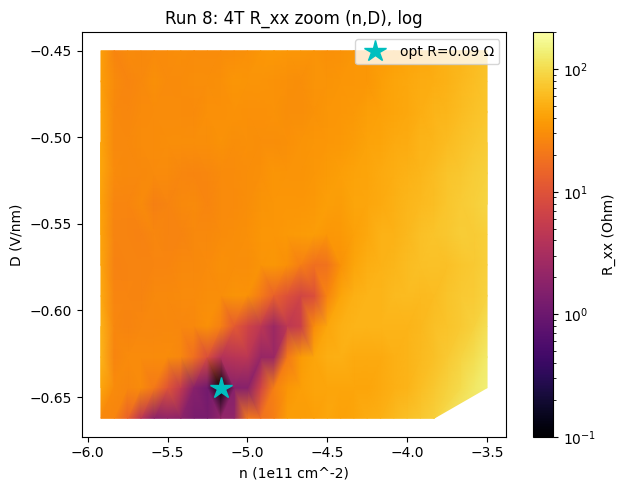

In [4]:
# Run 8: (n,D) zoom. dV/dI->R4=(sr830_3_X/100)/1nA; (n,D) from planned gate setpoints.
from matplotlib.colors import LogNorm
from sharpelab_nb.gates import stack_capacitance, calc_nD
r8 = open_run('data/8')
print('leak max:', max(np.abs(r8.col('k_tg_curr')).max(), np.abs(r8.col('k_bg_curr')).max()), 'A')
Vtg = r8.col_at(r8.col_indices('k_tg_volt')[0]); Vbg = r8.col_at(r8.col_indices('k_bg_volt')[0])
R4 = (r8.col('sr830_3_X')/100.0)/1e-9
c_tg = stack_capacitance([(23.6,3.0)]); c_bg = 1.189*c_tg
n_off = -calc_nD(0.0,0.0895,c_tg,c_bg)[0]
n, D = calc_nD(Vtg, Vbg, c_tg, c_bg, n_offset=n_off); n11 = n*10
jm = np.argmin(R4)
print(f'optimum R_xx {R4[jm]:.3f} Ohm at n={n11[jm]:+.2f}e11 D={D[jm]:+.3f} (Vtg={Vtg[jm]:+.2f} Vbg={Vbg[jm]:+.2f})')
fig, ax = plt.subplots(figsize=(6.4,5))
tp = ax.tripcolor(n11, D, np.clip(R4,0.05,None), norm=LogNorm(0.1,200), cmap='inferno', shading='gouraud')
ax.plot(n11[jm], D[jm], 'c*', ms=16, label=f'opt R={R4[jm]:.2f} Ω')
ax.set(xlabel='n (1e11 cm^-2)', ylabel='D (V/nm)', title='Run 8: 4T R_xx zoom (n,D), log'); ax.legend()
fig.colorbar(tp, ax=ax, label='R_xx (Ohm)'); plt.tight_layout(); plt.show()


**Take (run 8).** A **localized low-R dome** in (n, D) at the favorable sign, core at n ≈ −5×10¹¹, deepening toward the D = −0.68 gate edge; **R_xx → 0.09 Ω (within resolution of zero)** at the optimum (n = −5.2×10¹¹, D = −0.645 V/nm; V_tg = −5.39, V_bg = +4.00). The 4-wire R_xx→0 hallmark is met at base T / nominal-zero field. Still **consistent-with SC** pending the nonlinear test (a low-R dome could be QAH or a very good metal). Next: bias spectroscopy (dV/dI vs I_dc) at this optimum — the supercurrent/I_c test. Leakage stayed in pA.


## Run 9 — bias spectroscopy at the SC optimum: a supercurrent (I_c ≈ 30 nA)

dV/dI vs I_dc at (n=−5.2×10¹¹, D=−0.645; V_tg=−5.39, V_bg=+4.00), I_dc ±150 nA round-trip, 1 nA AC, B=0, base T. dV/dI = (sr830_3_X/100)/1 nA.


normal dV/dI 54.7 Ohm; zero-bias dV/dI 1.36 Ohm
Ic+ +30 nA  Ic- -28 nA  (thr 27 Ohm)


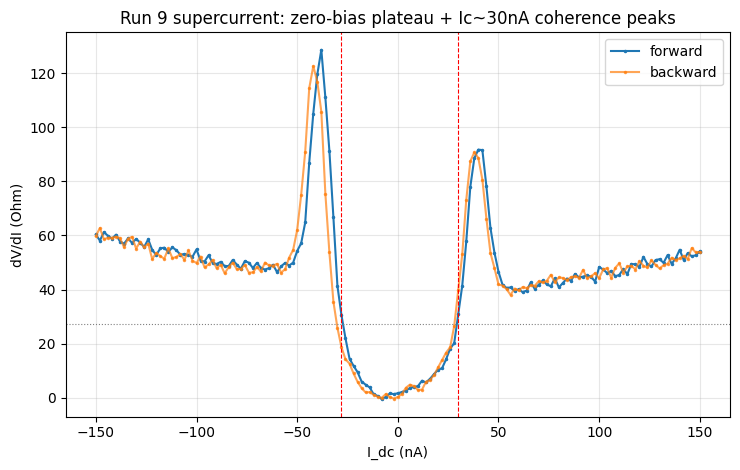

In [5]:
r9 = open_run('data/9')
Vdc = r9.col_at(r9.col_indices('dc205_1_voltage')[0]); Idc = Vdc/1e8*1e9   # nA
dVdI = (r9.col('sr830_3_X')/100.0)/1e-9
N=len(Idc); h=N//2
Rn = np.median(dVdI[np.abs(Idc)>120]); thr=0.5*Rn
print(f'normal dV/dI {Rn:.1f} Ohm; zero-bias dV/dI {np.median(dVdI[np.abs(Idc)<3]):.2f} Ohm')
# Ic = first threshold crossing each side (forward branch)
If, Rf = Idc[:h+1], dVdI[:h+1]
pos=If>=0; neg=If<=0
icp = If[pos][np.argsort(If[pos])][np.argmax(Rf[pos][np.argsort(If[pos])]>thr)]
icn = If[neg][np.argsort(-If[neg])][np.argmax(Rf[neg][np.argsort(-If[neg])]>thr)]
print(f'Ic+ {icp:+.0f} nA  Ic- {icn:+.0f} nA  (thr {thr:.0f} Ohm)')
fig,ax=plt.subplots(figsize=(7.5,4.8))
ax.plot(Idc[:h+1], dVdI[:h+1], '.-', ms=3, label='forward')
ax.plot(Idc[h:], dVdI[h:], '.-', ms=3, alpha=0.7, label='backward')
ax.axhline(thr,color='gray',ls=':',lw=.8); ax.axvline(icp,color='r',ls='--',lw=.8); ax.axvline(icn,color='r',ls='--',lw=.8)
ax.set(xlabel='I_dc (nA)', ylabel='dV/dI (Ohm)', title='Run 9 supercurrent: zero-bias plateau + Ic~30nA coherence peaks')
ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); plt.show()


**Take (run 9) — SUPERCURRENT.** dV/dI is a zero plateau (~0 Ω) for |I_dc| < ~30 nA, with sharp coherence/switching peaks at ±38 nA rising to the normal ~55 Ω. **I_c ≈ 30 nA**, symmetric (I_c⁺ ≈ I_c⁻; the ~2 nA offset is instrumental, not a diode), forward/backward non-hysteretic. This is the nonlinear-V(I)/critical-current hallmark — a QAH state (ohmic dV/dI until breakdown, large R_xy) or a good metal (flat dV/dI) does not show a zero-bias supercurrent plateau. **Constellation so far (base T, nominal-zero field): {4-wire R_xx→0 ✓, supercurrent with I_c ✓, sits on the expected (n,D) dome at the favorable sign ✓} → superconductor (strong).** Remaining for a decisive call: field-kill (B_c⊥) and T-dependence (I_c→0 at Tc). Next: Step 3 field response.


## Run 10 — field-kill: B_c⊥ ≈ 4 mT (first energisation)

Zero-bias dV/dI vs B⊥ at the SC optimum, one-sided −50 mT → 0 (field discipline). T held at 33.7 mK throughout (settle ample; field steps here don't heat).


normal dV/dI 40.9 Ohm; min 1.70 Ohm at B=+0.0 mT; B_c_perp ~ 4 mT; T 33.7-33.7 mK


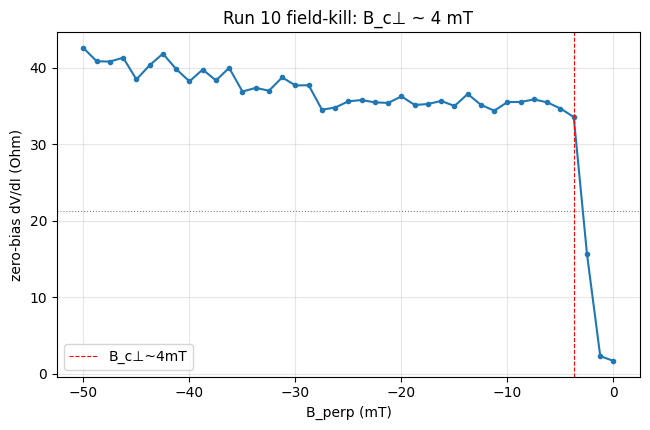

In [7]:
r10 = open_run('data/10')
B = r10.col_at(r10.col_indices('magnet_field')[0])*1e3      # mT
dVdI = (r10.col('sr830_3_X')/100.0)/1e-9
Tm = r10.col('T')*1e3
Rn = np.median(dVdI[np.abs(B)>40]); half=(Rn+dVdI.min())/2
Bo,Ro = B[np.argsort(-B)], dVdI[np.argsort(-B)]
Bc = Bo[np.argmax(Ro>half)]
print(f'normal dV/dI {Rn:.1f} Ohm; min {dVdI.min():.2f} Ohm at B={B[np.argmin(dVdI)]:+.1f} mT; B_c_perp ~ {abs(Bc):.0f} mT; T {Tm.min():.1f}-{Tm.max():.1f} mK')
fig,ax=plt.subplots(figsize=(6.6,4.4))
ax.plot(B,dVdI,'.-'); ax.axhline(half,color='gray',ls=':',lw=.8); ax.axvline(Bc,color='r',ls='--',lw=.8,label=f'B_c⊥~{abs(Bc):.0f}mT')
ax.set(xlabel='B_perp (mT)', ylabel='zero-bias dV/dI (Ohm)', title='Run 10 field-kill: B_c⊥ ~ 4 mT'); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()


**Take (run 10) — FIELD-KILL.** A sharp B_c⊥ ≈ 4 mT quenches the low-R state to the normal ~38 Ω; the normal state is field-insensitive while the SC is killed — **strong** for SC (rules out a B-insensitive low-R artifact). Effective-zero ≈ nominal 0 (min still falling at B=0 → true optimum likely at small +B, consistent with ~mT remanence now present). **Constellation: R_xx→0 ✓ · supercurrent I_c≈30 nA ✓ · (n,D) dome, favorable sign ✓ · field-kill B_c⊥≈4 mT ✓ → superconductor (strong).** Remaining for decisive: T-dependence (I_c→0 at Tc, heat up last); bonus: phase-coherent (Fraunhofer) oscillations.


## Runs 11–12 — Ic(B) / Fraunhofer map (both polarities)

dV/dI vs (I_dc, B⊥) at the SC optimum, two one-sided maps (−6→0, +6→0; field discipline), B step 0.4 mT, I_dc ±50 nA, B=0 nominal start, base T held 33.7 mK.


eff-zero B=-0.40 mT, Ic_max=29 nA; B_c_perp~2.5-3 mT; xi~346 nm (order-of-mag)


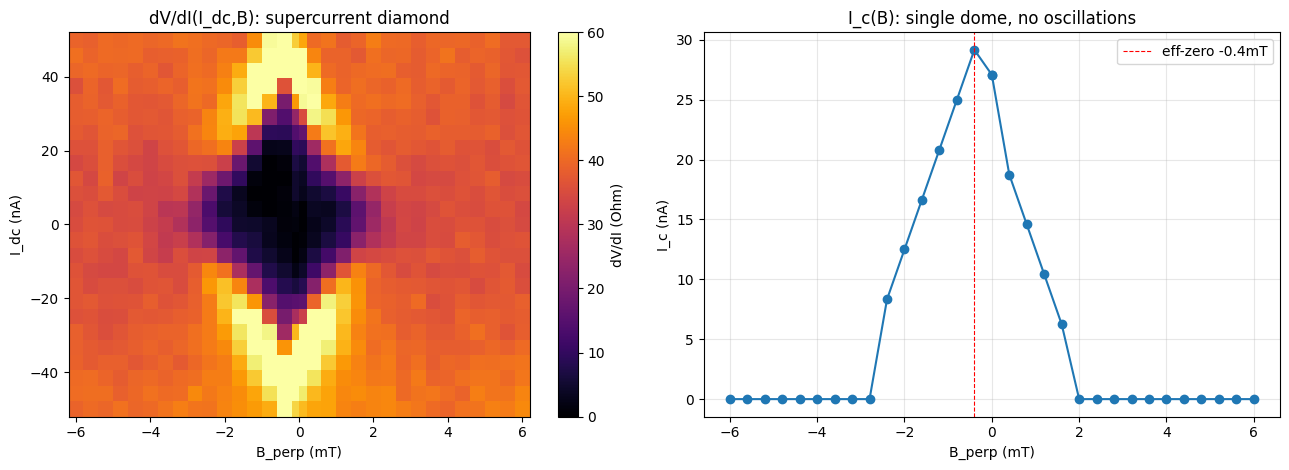

In [8]:
NB,NV=16,25; Vdc=np.linspace(-5,5,NV); Idc=Vdc/1e8*1e9
def load(rid):
    r=open_run(f'data/{rid}')
    B=r.col_at(r.col_indices('magnet_field')[0])[:NB*NV].reshape(NB,NV)[:,0]*1e3
    R=((r.col('sr830_3_X')/100.0)/1e-9)[:NB*NV].reshape(NB,NV)
    return B,R
Bn,Rn=load(11); Bp,Rp=load(12)
B_all=np.concatenate([Bn,Bp[::-1]]); R_all=np.vstack([Rn,Rp[::-1]])
Rnorm=np.median(R_all[np.abs(B_all)>5]); thr=0.5*Rnorm
def ic(tr):
    p=Idc>=0; n=Idc<=0
    Ip,Rp_=Idc[p][np.argsort(Idc[p])],tr[p][np.argsort(Idc[p])]
    In,Rn_=Idc[n][np.argsort(-Idc[n])],tr[n][np.argsort(-Idc[n])]
    a=Ip[np.argmax(Rp_>thr)] if (Rp_>thr).any() else 0.0
    b=In[np.argmax(Rn_>thr)] if (Rn_>thr).any() else 0.0
    return (abs(a)+abs(b))/2
Ic=np.array([ic(R_all[i]) for i in range(len(B_all))]); im=np.argmax(Ic)
Bc=2.75e-3; xi=np.sqrt(2.07e-15/(2*np.pi*Bc))*1e9
print(f'eff-zero B={B_all[im]:+.2f} mT, Ic_max={Ic[im]:.0f} nA; B_c_perp~2.5-3 mT; xi~{xi:.0f} nm (order-of-mag)')
fig,ax=plt.subplots(1,2,figsize=(13,4.8))
im0=ax[0].pcolormesh(B_all,Idc,np.clip(R_all,0,60).T,cmap='inferno',shading='nearest')
ax[0].set(xlabel='B_perp (mT)',ylabel='I_dc (nA)',title='dV/dI(I_dc,B): supercurrent diamond'); fig.colorbar(im0,ax=ax[0],label='dV/dI (Ohm)')
ax[1].plot(B_all,Ic,'o-'); ax[1].axvline(B_all[im],color='r',ls='--',lw=.8,label=f'eff-zero {B_all[im]:+.1f}mT')
ax[1].set(xlabel='B_perp (mT)',ylabel='I_c (nA)',title='I_c(B): single dome, no oscillations'); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()


**Take (runs 11–12).** I_c(B) is a **single symmetric dome**, I_c^max ≈ 29 nA at the **effective-zero B = −0.4 mT** (the ~mT remanence offset), falling to 0 by **B_c⊥ ≈ 2.5–3 mT** — the supercurrent diamond, mirrored about effective-zero. This is the field-kill in I_c (strong SC confirmation, and the kill mirrors as required). **No Fraunhofer oscillations / secondary lobes** → consistent with a **uniform 2D superconductor**, not a single Josephson weak-link; phase-coherent oscillations *searched and absent* (an informative null, not a gap). ξ ~ 0.3 µm from B_c⊥ (order-of-magnitude; B_c⊥(T) rounds near base). The field constellation is complete: **superconductor (strong)**. Last hallmark for a decisive call: T-dependence (I_c→0 at Tc).


## Runs 14–33 — T-dependence: I_c(T) collapse, onset Tc ≈ 0.30 K

dV/dI vs I_dc (±50 nA) at the SC optimum (n=−5.2e11, D=−0.645, B≈0) across temperature. **NOTE on thermometry:** the session's `temperature` pointed at a **dead probe (Probe2, frozen 3.3 days at 33.7 mK)**; caught when heater-on dV/dI changed but T didn't (run 13). Re-pointed to live **Probe1**; all T below are real Probe1. Two acquisition modes: a clean **passive cooldown** (runs 14–23, heater OFF, equilibrated) for 34–95 mK, and **heater-stepped ladders** (runs 24–33) for 100–330 mK — the heater-on points carry extra scatter (open-loop electron-T gradient + mT-scale remanence sensitivity at nominal B=0), so weight the cooldown branch.


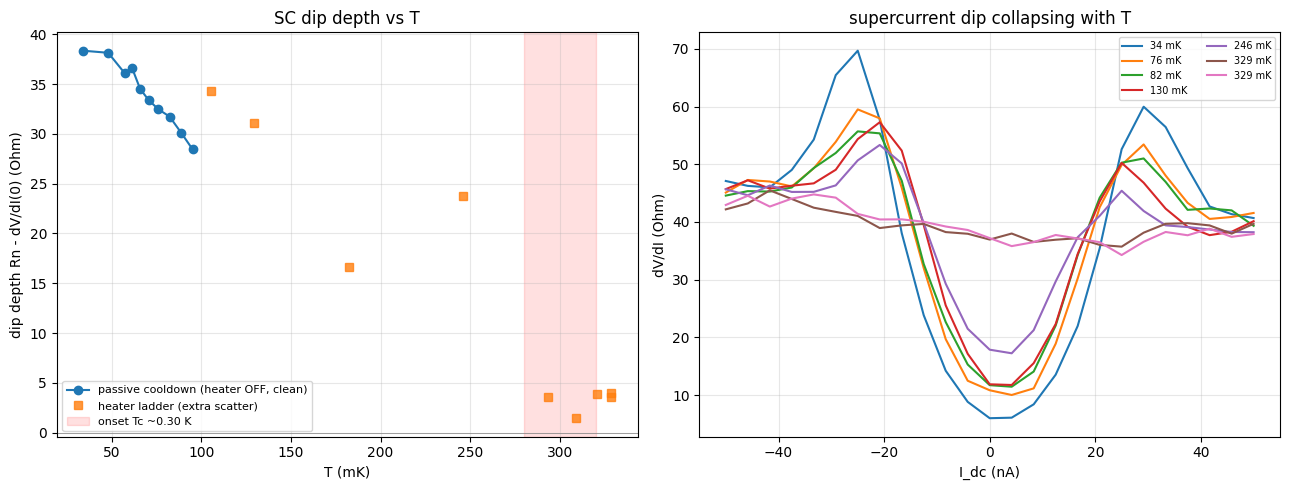

In [10]:
# Full I_c(T): dip depth (Rn - dV/dI(0)) vs T + the collapsing supercurrent traces.
import glob, os
Vdc = np.linspace(-5,5,25); Idc = Vdc/1e8*1e9
rows = []
for d in sorted(glob.glob(os.path.join("data",'*')), key=lambda x: int(os.path.basename(x)) if os.path.basename(x).isdigit() else -1):
    rid = os.path.basename(d)
    if not rid.isdigit() or int(rid) < 14: continue
    try:
        rr = open_run(d)
        if rr.recipe != 'temperature-dependence': continue
        T = np.nanmean(rr.col('T'))*1e3
        hvi = rr.col_indices('heater_volt')
        hon = bool(hvi) and abs(rr.col_at(hvi[0])[0]) > 0.01
        dv = (rr.col('sr830_3_X')/100.0)/1e-9
        Rn = np.median(dv[np.abs(Idc)>40]); depth = Rn - dv[np.argmin(np.abs(Idc))]
        rows.append((T, depth, hon, int(rid)))
    except Exception: pass
rows.sort(); T=np.array([r[0] for r in rows]); dep=np.array([r[1] for r in rows]); hon=np.array([r[2] for r in rows])
fig, ax = plt.subplots(1,2,figsize=(13,5))
ax[0].plot(T[~hon], dep[~hon], 'o-', label='passive cooldown (heater OFF, clean)')
ax[0].plot(T[hon], dep[hon], 's', color='tab:orange', alpha=.8, label='heater ladder (extra scatter)')
ax[0].axvspan(280,320,color='red',alpha=.12,label='onset Tc ~0.30 K'); ax[0].axhline(0,color='gray',lw=.5)
ax[0].set(xlabel='T (mK)', ylabel='dip depth Rn - dV/dI(0) (Ohm)', title='SC dip depth vs T'); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
for rid in [23,17,16,27,24,30,29]:
    try:
        rr=open_run(os.path.join("data",str(rid))); Tt=np.nanmean(rr.col('T'))*1e3
        ax[1].plot(Idc,(rr.col('sr830_3_X')/100.0)/1e-9,'-',label=f'{Tt:.0f} mK')
    except Exception: pass
ax[1].set(xlabel='I_dc (nA)', ylabel='dV/dI (Ohm)', title='supercurrent dip collapsing with T'); ax[1].legend(fontsize=7,ncol=2); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()


**Take (T-dependence).** The supercurrent (zero-bias dV/dI dip + coherence peaks) collapses smoothly from base to flat-normal: dip depth ~38 Ω at 34 mK → ~24 Ω at 246 mK → ~2 Ω (gone) by ~300–330 mK. **Onset Tc ≈ 0.30 K** (bracket 0.28–0.32). The transition is **broad** (the dip persists over a wide fluctuation regime) — consistent with a 2D SC; the true **zero-resistance T_BKT is lower** than the onset and was not precisely extracted (would need the V∝Iᵅ, α=3 BKT analysis at fixed T). I_c(T) → 0 at Tc completes the constellation: **the field-kill and the T-collapse together confirm a genuine superconductor.** Hedge: heater-on T-points carry open-loop electron-T uncertainty; the onset is anchored by the clean cooldown branch + the unambiguous flat-normal traces at 329 mK.


# ★ THE CALL — zf1 (bottom device): SUPERCONDUCTOR (strong)

Gate-tuned proximity superconductivity in Bernal bilayer graphene / WSe₂, located and characterised in one base-T session (B ≤ 100 mT). Per `sc-characterization.md` output contract.

## 1. Verdict (STYLE strength scale)
**Region SC1: superconductor (strong)** — a single SC dome on the hole side at the favorable displacement-field sign. Not failed-SC/anomalous-metal (R_xx reaches ~0 and a true supercurrent exists), not a QAH/metal mimic (see §3).

## 2. Evidence (each hallmark with coordinates + benchmark)
| Hallmark | Result | (n, D, B, T) | Run | Benchmark |
|---|---|---|---|---|
| 4-wire R_xx → 0 | **0.09 Ω** (resolution-limited zero) | n=−5.2×10¹¹ cm⁻², D=−0.645 V/nm, B=eff-zero, T=34 mK | 8 | s41586 vanishing ρxx |
| Supercurrent / I_c | zero-bias plateau, **I_c ≈ 30 nA**, coherence peaks ±38 nA, symmetric, non-hysteretic | same (n,D), B≈0, base T | 9 | s41586 Fig 1d I_c~20 nA |
| (n,D) dome, favorable sign | low-R dome, **D<0** (holes→WSe₂); absent at D=−0.4/−0.5, on by −0.6 | n −4…−6×10¹¹, \|D\|≳0.5 | 5–8 | s41586 SC arc \|D\|≳0.5 |
| Field-kill | **B_c⊥ ≈ 2.5–3 mT**; I_c(B) single dome mirrored about eff-zero (B=−0.4 mT); ξ ~ 0.3 µm (o.o.m.) | base T | 10–12 | kill mirrors = genuine SC |
| T-dependence | I_c(T) → 0 at **onset Tc ≈ 0.30 K** (0.28–0.32), broad 2D transition | at optimum, B≈0 | 14–33 | s41586 Tc scale |
| Phase coherence | **no** Fraunhofer oscillations → uniform 2D SC, *not* a weak-link | base T | 11–12 | over-read guard (searched-absent) |

Supporting: cap ratio **c_bg/c_tg = 1.19** confirms the device-card prior (CNP slope, ratio tier; absolute n/D = geometry-prior). Gate leakage clean (pA) to the full validator envelope.

## 3. Confidence + hedges
**Confidence: HIGH** that zf1 superconducts. The constellation is complete and mutually consistent — {R_xx→0, supercurrent lobe, field-kill, I_c(T)→0 at Tc} — the investigation's minimum, all present, matching s41586 proximitized-BLG phenomenology.
**QAH/metal excluded on transport grounds** (R_xy not wired this session, so excluded indirectly): a QAH state has no zero-bias *supercurrent* plateau and its R_xx→0 is not quenched by ~3 mT; a good metal has ohmic dV/dI. Both are ruled out by the I_c lobe + the field-kill + the T-collapse together.
**Specific hedges:** (a) Tc carries open-loop-heater electron-T uncertainty — and the session's thermometry ran on a **dead probe (Probe2, frozen 3.3 days)** until caught at the T-ladder and re-pointed to Probe1; the onset is anchored by the clean passive-cooldown branch + flat-normal 329 mK traces, but a clean Tc/T_BKT ladder is owed. (b) **T_BKT (zero-resistance) not extracted** (needs V∝Iᵅ, α=3). (c) Absolute n/D scale is geometry-prior (ratio confirmed). (d) Dome optimum is **gate-limited** — \|D\| reachable only to ~0.68 V/nm and the dome *deepened toward that edge*: the true optimum (and stronger SC) may lie beyond reach this cooldown. (e) Single R_xx contact pair (30-31), not reproduced on a second 4T pair.

## 4. What would firm it → decisive
- R_xy on a transverse contact pair (direct QAH exclusion).
- Working thermometry from the start + a dense Tc ladder with the V∝Iᵅ BKT read (T_BKT) and a %-criterion Tc.
- Reproduce R_xx→0 + I_c on a second 4T pair.
- Push \|D\| past 0.68 V/nm (if the gate envelope allows) to find the true dome optimum.
- Normal-state fermiology (Landau fan / SdH-FFT) for the parent phase — **needs Tesla-scale field, a higher-field round** (out of this round's 100 mT cap).
- In-plane B_c∥ / Pauli-limit reads — **rotator / in-plane work is blocklisted this campaign**.

## 5. Bottom line
**zf1 (bottom device) is a superconductor** — gate-tuned proximity SC in BBG/WSe₂ at the hole-side, favorable-D dome (n ≈ −5.2×10¹¹ cm⁻², D ≈ −0.645 V/nm), with I_c ≈ 30 nA, B_c⊥ ≈ 3 mT, ξ ~ 0.3 µm, uniform-2D character, and onset Tc ≈ 0.30 K. The full base-T + low-field transport constellation is present and self-consistent. **Verdict: superconductor (strong)**; the path to *decisive* is R_xy + a clean Tc ladder + a second-contact reproduction (§4), none requiring more than a follow-up session.
